# 02. 토지피복 비율 만들기 (v2: 실제 데이터)
**작성자: B (정준)**
결과물: `data_processed/features.csv`

**v2에서 바뀐 점**
- `USE_DUMMY = False` (예슬 `labels.csv` 사용, 센서 963개 --> 961개)
- WorldCover 지도를 코랩에서 바로 내려받는 칸 추가
- 한강까지 거리(`dist_han_m`) 계산 추가
- 결과 점검 칸, 300m로 정한 이유 칸 추가

In [ ]:
# ── 공통 설정 (모든 노트북 맨 위에 그대로 두기) ──
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/AICEE_project'   # 모두 같은 경로 (공유 폴더를 '내 드라이브에 바로가기 추가' 해야 함)
DATA = f'{BASE}/data_processed'
RESULTS = f'{BASE}/results'

import sys
sys.path.append(f'{BASE}/shared')
RANDOM_STATE = 42

USE_DUMMY = False   # 진짜 데이터 사용 (예슬 labels.csv 완성, 11/26)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


> **6주차 누수 점검**: 입력 변수는 '예측하는 순간에 알 수 있는 값'만. 토지피복·한강 거리는 OK. 같은 시각 다른 센서의 기온 같은 건 넣지 않기.

In [ ]:
!pip -q install rasterio

## 1) WorldCover 지도 받기
ESA WorldCover 10m 2021 (v200), 서울이 들어 있는 3°×3° 타일 `N36E126` (북위 36~39°, 동경 126~129°).
공식 공개 저장소(AWS)에서 바로 받아 `data_raw/worldcover/`에 저장.

In [ ]:
import os, urllib.request
WC_DIR = f'{BASE}/data_raw/worldcover'
os.makedirs(WC_DIR, exist_ok=True)
NAME = 'ESA_WorldCover_10m_2021_v200_N36E126_Map.tif'
URL = f'https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/{NAME}'
out = f'{WC_DIR}/{NAME}'
if not os.path.exists(out):
    print('내려받는 중... (수십~수백 MB라 1~3분 걸릴 수 있음)')
    try:
        urllib.request.urlretrieve(URL, out)
    except Exception as e:
        if os.path.exists(out):
            os.remove(out)   # 반쯤 받다 끊긴 파일은 지우기
        raise RuntimeError(f'다운로드 실패: {e}\nhttps://esa-worldcover.org 에서 N36E126 타일을 직접 받아 {WC_DIR} 에 넣어도 됨')
print(NAME, round(os.path.getsize(out) / 1e6, 1), 'MB')

ESA_WorldCover_10m_2021_v200_N36E126_Map.tif 87.4 MB


지도 정보 확인: `EPSG:4326`, 경계가 (126, 36, 129, 39) 근처, 해상도 약 0.0000833°(≈10m)면 정상

In [ ]:
import glob, rasterio
tif = glob.glob(f'{BASE}/data_raw/worldcover/*.tif')[0]
with rasterio.open(tif) as src:
    print(src.crs, src.bounds, src.res)

EPSG:4326 BoundingBox(left=126.0, bottom=36.0, right=129.0, top=39.0) (8.333333333333333e-05, 8.333333333333333e-05)


## 2) 먼저 센서 10개로 테스트 → 숫자가 그럴듯한지 확인 (공원 옆 센서는 녹지↑?)

In [ ]:
import pandas as pd
from landcover import add_landcover_columns
sensors = pd.read_csv(f'{DATA}/labels_dummy.csv' if USE_DUMMY else f'{DATA}/labels.csv')[['sensor_id', 'gu', 'lat', 'lon']]
add_landcover_columns(sensors.head(10), tif, radius_m=300)

,sensor_id,gu,lat,lon,green_300,impervious_300,water_300
0,V02Q1940655,종로구,37.580051,126.985146,0.095686,0.901422,0.0
1,V02Q1940539,종로구,37.576920,127.004514,0.053266,0.946734,0.0
2,V02Q1940737,종로구,37.605426,126.967435,0.423855,0.575904,0.0
3,V02Q1940721,종로구,37.586059,127.000838,0.071825,0.928175,0.0
4,V02Q1940522,종로구,37.577075,127.012367,0.068691,0.930827,0.0
5,V02Q1940499,종로구,37.574960,126.970272,0.102916,0.892986,0.0
6,V02Q1940695,종로구,37.571837,126.962032,0.020969,0.979031,0.0
7,V02Q1940716,종로구,37.575953,126.958182,0.419137,0.580622,0.0
8,V02Q1940649,종로구,37.571340,126.970504,0.270186,0.726440,0.0
9,V02Q1940232,종로구,37.585033,126.981876,0.354784,0.641600,0.0


In [ ]:
# 서울시 원본 위치정보 좌표 오류로 제외
# OC3KL240004: 위도 37.06195 (주소는 은평구 녹번동)
# OC3DL220020, OC3DL220021: 성동구 금호동인데 좌표가 관악구 신림동 센서와 동일
BAD = ['OC3KL240004', 'OC3DL220020', 'OC3DL220021']
sensors = sensors[~sensors['sensor_id'].isin(BAD)].reset_index(drop=True)
print('제외 후 센서 수:', len(sensors))

제외 후 센서 수: 961


## 3-1) 한강까지 거리 (`dist_han_m`)
방법: WorldCover의 '물(80)' 칸 중에서
1. **폭 약 100m보다 좁은 물길은 지움** (지천·개천·저수지 가장자리 정리, `binary_opening`)
2. 남은 덩어리 중 **가장 큰 것 = 한강**으로 봄
3. 센서마다 한강 칸까지의 **가장 가까운 직선거리(m)**

→ 별도 데이터 없이 같은 지도로 재현 가능. 아래 그림으로 한강만 제대로 잡혔는지 **눈으로 꼭 확인**하기

한계(보고서용): 큰 지천의 하구 부분은 한강에 일부 붙어 잡힐 수 있음. 바람길 효과를 '거리'로만 단순화함.

In [ ]:
import numpy as np
from scipy import ndimage
from scipy.spatial import cKDTree
from rasterio.windows import from_bounds

SEOUL = (126.70, 37.38, 127.25, 37.74)   # 서울 + 여유 (서, 남, 동, 북)
M = 111_320                              # 위도 1도 ≈ 111,320 m
COS = np.cos(np.radians(37.55))          # 서울 위도에서 경도 1도는 이만큼 짧아짐

with rasterio.open(tif) as src:
    win = from_bounds(*SEOUL, src.transform)
    arr = src.read(1, window=win)
    t = src.window_transform(win)

water = (arr == 80)
water = ndimage.binary_closing(water, structure=np.ones((3, 3)), iterations=6)  # 다리로 끊긴 강 잇기
wide = ndimage.binary_opening(water, structure=np.ones((3, 3)), iterations=5)   # 폭 ~100m 미만 물길 제거
lab, n = ndimage.label(wide)
sizes = ndimage.sum(wide, lab, range(1, n + 1))
han = lab == (np.argmax(sizes) + 1)      # 가장 큰 물 덩어리 = 한강
print('한강으로 잡힌 면적:', round(han.sum() * 100 / 1e6, 1), 'km²  (대략 30~60이면 그럴듯)')

r, k = np.nonzero(han)
tree = cKDTree(np.c_[(t.c + (k + 0.5) * t.a) * M * COS, (t.f + (r + 0.5) * t.e) * M])

def dist_han(lats, lons):
    d, _ = tree.query(np.c_[np.asarray(lons) * M * COS, np.asarray(lats) * M])
    return np.round(d, 0)

한강으로 잡힌 면적: 75.0 km²  (대략 30~60이면 그럴듯)


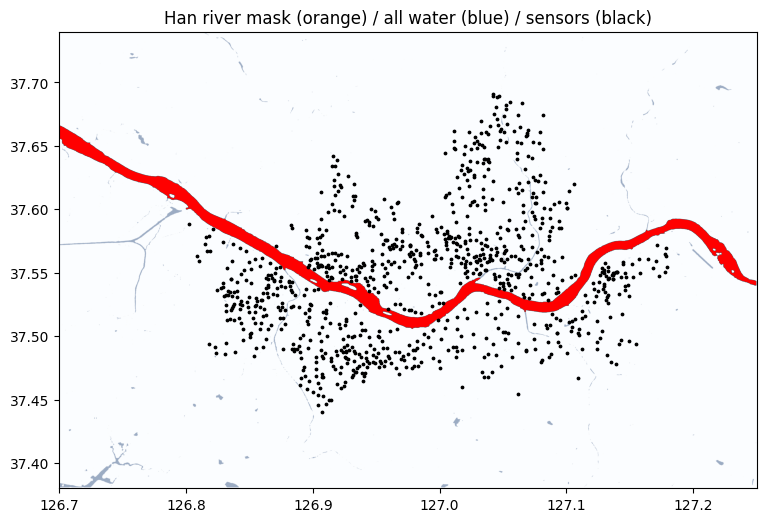

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 6))
ext = [t.c, t.c + t.a * arr.shape[1], t.f + t.e * arr.shape[0], t.f]
ax.imshow(water, cmap='Blues', extent=ext, alpha=0.4)
ax.imshow(np.ma.masked_where(~han, han), cmap='autumn', extent=ext)
ax.scatter(sensors['lon'], sensors['lat'], s=3, c='k')
ax.set_title('Han river mask (orange) / all water (blue) / sensors (black)')
plt.savefig(f'{RESULTS}/B_fig1_han_mask.png', dpi=200, bbox_inches='tight')
plt.show()

## 3-2) 전체 센서 계산 → `features.csv` 저장

In [ ]:
feats = add_landcover_columns(sensors, tif, radius_m=300)
feats['dist_han_m'] = dist_han(feats['lat'], feats['lon'])
feats.to_csv(f'{DATA}/features.csv', index=False)
feats.describe().round(3)

,lat,lon,green_300,impervious_300,water_300,dist_han_m
count,961.000,961.000,961.000,961.000,961.000,961.000
mean,37.549,126.985,0.154,0.833,0.008,3905.122
std,0.051,0.088,0.171,0.180,0.039,3092.780
min,37.440,126.802,0.000,0.009,0.000,43.000
25%,37.510,126.915,0.025,0.740,0.000,1561.000
50%,37.548,126.985,0.088,0.903,0.000,3214.000
75%,37.576,127.052,0.237,0.971,0.000,5178.000
max,37.691,127.179,0.991,1.000,0.413,15382.000


## 4) 결과 점검
- 센서 수가 961개 인가 (오류로 인해 추가 2개 더 제외)
- 빈칸(NaN)이 없는가
- 녹지+불투수면+물 합이 1 이하인가 (나머지는 나지·농경지 등)

In [ ]:
print('센서 수:', len(feats), '/ labels:', len(sensors))
print('빈칸 수:\n', feats.isna().sum())
s = feats['green_300'] + feats['impervious_300'] + feats['water_300']
print('세 비율 합: 최소', round(s.min(), 3), '최대', round(s.max(), 3))
print('한강 거리(m): 최소', feats['dist_han_m'].min(), '최대', feats['dist_han_m'].max())

센서 수: 961 / labels: 961
빈칸 수:
 sensor_id         0
gu                0
lat               0
lon               0
green_300         0
impervious_300    0
water_300         0
dist_han_m        0
dtype: int64
세 비율 합: 최소 0.873 최대 1.0
한강 거리(m): 최소 43.0 최대 15382.0


## 5) 변수끼리 상관관계 (2주차 EDA)
녹지+불투수면+물 ≈ 100%라서 서로 강하게 얽혀 있을 것 → 모델 2에서 VIF로 확인

In [ ]:
feats[['green_300', 'impervious_300', 'water_300', 'dist_han_m']].corr().round(2)

,green_300,impervious_300,water_300,dist_han_m
green_300,1.00,-0.97,0.06,0.15
impervious_300,-0.97,1.00,-0.28,-0.11
water_300,0.06,-0.28,1.00,-0.17
dist_han_m,0.15,-0.11,-0.17,1.00


# 6) 300m로 정한 이유
100·300·500m로 녹지 비율을 각각 계산해서 열섬과의 상관을 비교.

In [ ]:
lab_df = pd.read_csv(f'{DATA}/labels.csv')
rows = []
for r_m in [100, 300, 500]:
    f = add_landcover_columns(sensors, tif, radius_m=r_m).merge(lab_df[['sensor_id', 'uhi_day', 'uhi_night']], on='sensor_id')
    rows.append({'반경(m)': r_m,
                 '녹지-낮 상관': round(f[f'green_{r_m}'].corr(f['uhi_day']), 3),
                 '녹지-밤 상관': round(f[f'green_{r_m}'].corr(f['uhi_night']), 3),
                 '불투수-밤 상관': round(f[f'impervious_{r_m}'].corr(f['uhi_night']), 3)})
pd.DataFrame(rows)

,반경(m),녹지-낮 상관,녹지-밤 상관,불투수-밤 상관
0,100,-0.338,-0.455,0.449
1,300,-0.320,-0.523,0.495
2,500,-0.315,-0.561,0.521


## 02_features_B 보고서용 메모(정준)

**데이터**
- 토지피복: ESA WorldCover 10m 2021 (v200), 타일 N36E126 (공개 데이터, 가입·승인 불필요)
- 녹지 = 나무·관목·초지·농경지·습지(10, 20, 30, 40, 90) / 불투수 = 건물·시가지(50) / 물 = 영구 수역(80)
- 센서 위치: 예슬 labels.csv의 lat, lon 사용

**결과**
- features.csv: 센서 961개, 25개 구 전부, 빈칸 없음
- 열: sensor_id, gu, lat, lon, green_300, impervious_300, water_300, dist_han_m

**제외한 센서 (서울시 원본 위치정보 좌표 오류, 원본 파일은 수정하지 않음)**
- OC3KL240004: 위도 37.06195로 서울 밖 (주소는 은평구 녹번동 282-3)
- OC3DL220020, OC3DL220021: 성동구 금호동 주소인데 좌표가 관악구 신림동 센서와 똑같음 (220020은 labels 단계에서 이미 제외)
- 발견 경위: 센서를 지도에 찍어 검증하다 발견 → 열린데이터광장 원본 엑셀에서 같은 오류 확인
- labels.csv 963개 → features.csv 961개

**한강까지 거리 (dist_han_m) 계산 방법** (팀 확인 전 초안: 아래 방법으로 계산함. 팀 합의 후 확정)
1. WorldCover에서 물(80) 칸만 고름
2. 다리 때문에 한강이 끊겨 보여서, 폭 약 100m 이하 틈을 이어 붙임 (binary_closing)
3. 폭 약 100m보다 좁은 물길(지천·개천)은 지움 (binary_opening)
4. 남은 물 덩어리 중 가장 큰 것 = 한강 본류
5. 센서마다 한강까지 가장 가까운 직선거리(m)
- 검증: 결과 그림(results/B_fig1_han_mask.png)으로 한강 전체가 잡혔는지 눈으로 확인
- 처음엔 다리 때문에 한강이 토막나 김포 쪽 일부만 잡혔음 → 2번 단계를 추가해 해결

**한계**
- 지도는 2021년, 기온은 2026년 8월: 그 사이 재개발된 곳은 토지피복이 다를 수 있음
- 바람길 효과를 '한강까지 거리' 하나로 단순화함
- 큰 지천의 하구 일부가 한강에 붙어 잡혔을 수 있음

**왜 반경 300m인가**

처음에는 '동네(블록) 단위'의 차이를 보려는 목적에 맞춰 300m로 정했다. 센서 961개가 서울 약 605km²에 퍼져 있어 센서 한 개가 맡는 면적은 평균 약 0.63km²이다. 반경 300m 원(약 0.28km²)은 이보다 작아 이웃 센서와 겹치는 부분이 적지만, 500m 원(약 0.79km²)은 이보다 커서 가까운 센서끼리 같은 땅을 많이 공유하게 된다. 반경이 클수록 센서마다의 차이가 흐려진다는 뜻이다.

이 선택이 결과를 크게 좌우하는지 확인하려고 100·300·500m로 녹지·불투수면 비율을 각각 계산해 열섬과의 상관을 비교했다.

| 반경 | 녹지-낮 | 녹지-밤 | 불투수-밤 |
|---|---|---|---|
| 100m | −0.338 | −0.455 | 0.449 |
| 300m | −0.320 | −0.523 | 0.495 |
| 500m | −0.315 | −0.561 | 0.521 |

세 반경 모두 방향은 예상과 같았다(녹지가 많을수록 시원, 불투수면이 많을수록 더움). 낮보다 밤의 관계가 뚜렷했는데, 낮에 건물과 도로가 머금은 열을 밤에 내놓는 열섬의 특성과 맞는다. 밤에는 반경이 넓을수록 관계가 조금씩 강해져, 밤 기온은 바로 옆보다 더 넓은 주변 환경의 영향을 받는 것으로 보인다.

다만 300m와 500m의 차이는 작았고(녹지-밤 −0.52 vs −0.56), 500m는 위에서 말한 겹침 문제로 동네 간 차이를 구분하는 힘이 약해진다. 그래서 300m를 유지했다.

한계: 이 비교는 테스트용 구까지 포함한 전체 데이터로 했기 때문에, 결과를 보고 반경을 고르면 테스트 데이터를 미리 본 셈이 된다. 반경을 바꾼다면 학습 데이터 안의 교차검증으로 다시 비교해 정해야 한다.

**생성형 AI 사용 내역**
- 도구: Claude
- 사용한 곳: 한강 거리 계산 방법, 결과 점검 칸 확인, 에러 해결, 좌표 오류 원인 추적
- 확인 방법: 가짜 지도로 거리 계산을 먼저 검증, 실제 결과는 한강 그림과 숫자(구별 거리)로 직접 확인
- 오류 수정: 처음 한강 계산이 다리 때문에 잘못 나와 그림으로 발견하고 고침